In [ ]:
import numpy as np
from numpy import array, argmax
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from  sklearn.preprocessing import LabelEncoder, OneHotEncoder
from  sklearn.preprocessing import StandardScaler, MinMaxScaler
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from PIL import Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df=pd.read_csv('/content/drive/MyDrive/EDA PROJECT NYC AIR BNB ANALYSIS/AB_NYC_2019.csv')

In [ ]:
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(48895, 16)

In [ ]:
df.size

782320

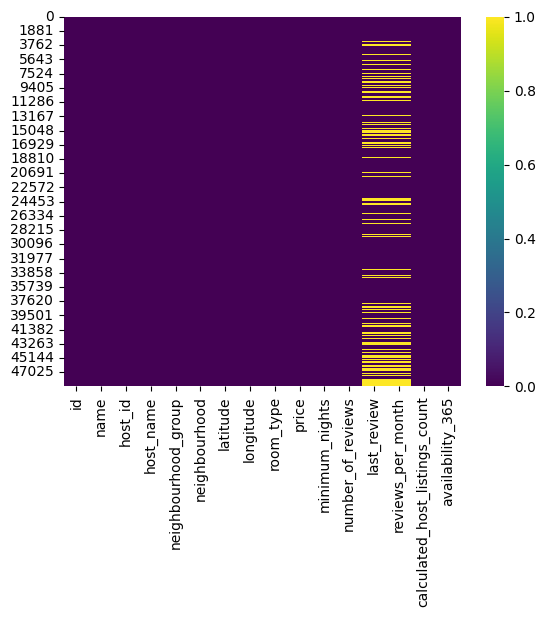

In [ ]:
sns.heatmap(df.isnull(),cmap='viridis')
plt.show()

In [ ]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [ ]:
df_clean=df.drop(['id','name','host_name'],axis=1)

In [ ]:
df_clean.columns

Index(['host_id', 'neighbourhood_group', 'neighbourhood', 'latitude',
       'longitude', 'room_type', 'price', 'minimum_nights',
       'number_of_reviews', 'last_review', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

In [ ]:
df_clean.shape

(48895, 13)

In [ ]:
df_clean['reviews_per_month'] = (
    df_clean['reviews_per_month'].fillna(0)
)

In [ ]:
df_clean.isnull().sum()

,0
host_id,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
last_review,10052


In [ ]:
df_clean[
    df_clean['reviews_per_month'].isnull()
]['number_of_reviews'].value_counts()

,count
number_of_reviews,


In [ ]:
df_clean.loc[
    (df_clean['number_of_reviews'] == 0) &
    (df_clean['reviews_per_month'].isna()),
    'reviews_per_month'
] = 0

In [ ]:
df_clean.isnull().sum()

,0
host_id,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
last_review,10052


In [ ]:
df_clean.head()

,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2787,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2845,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,4632,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1,365
3,4869,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,7192,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df_clean.sample(20)

,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
10295,10447370,Brooklyn,Williamsburg,40.71670,-73.95272,Entire home/apt,210,2,2,2015-12-02,0.04,1,0
25551,3656083,Brooklyn,Greenpoint,40.73237,-73.95952,Private room,61,10,2,2018-07-13,0.09,2,0
25717,16401899,Manhattan,East Harlem,40.78998,-73.94600,Entire home/apt,120,1,61,2019-06-18,2.67,1,1
27193,56391145,Brooklyn,Greenpoint,40.72468,-73.95230,Entire home/apt,150,3,0,NaN,0.00,2,0
27799,5443000,Manhattan,East Village,40.73103,-73.98233,Entire home/apt,299,2,21,2019-06-11,1.08,2,2
26856,154106207,Queens,Astoria,40.76031,-73.91583,Private room,180,6,0,NaN,0.00,1,83
21185,102482048,Brooklyn,Bushwick,40.68210,-73.90856,Private room,30,2,54,2019-06-14,1.87,4,179
5445,20433199,Manhattan,East Village,40.72186,-73.97663,Entire home/apt,125,14,2,2018-08-26,0.04,1,3
18410,16756301,Manhattan,Chelsea,40.74370,-73.99896,Entire home/apt,249,7,70,2019-07-02,2.03,1,266
42677,52584817,Manhattan,East Village,40.72353,-73.97646,Entire home/apt,150,2,5,2019-06-28,1.33,1,4


In [ ]:
df_clean['last_review'] = pd.to_datetime(
    df_clean['last_review'],
    errors='coerce'
)

In [ ]:
df_clean['last_review'].isnull().sum()

np.int64(10052)

In [ ]:
df_clean.loc[
    df_clean['last_review'].isnull(),
    'number_of_reviews'
].value_counts()

,count
number_of_reviews,
0,10052


In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   host_id                         48895 non-null  int64         
 1   neighbourhood_group             48895 non-null  object        
 2   neighbourhood                   48895 non-null  object        
 3   latitude                        48895 non-null  float64       
 4   longitude                       48895 non-null  float64       
 5   room_type                       48895 non-null  object        
 6   price                           48895 non-null  int64         
 7   minimum_nights                  48895 non-null  int64         
 8   number_of_reviews               48895 non-null  int64         
 9   last_review                     38843 non-null  datetime64[ns]
 10  reviews_per_month               48895 non-null  float64       
 11  ca

In [ ]:
df_clean.select_dtypes(include='object').columns

Index(['neighbourhood_group', 'neighbourhood', 'room_type'], dtype='object')

In [ ]:
for col in df_clean.select_dtypes(include='object').columns:
    print(col, ":", df_clean[col].nunique())
    print(df_clean[col].unique()[:10])
    print("-" * 40)

neighbourhood_group : 5
['Brooklyn' 'Manhattan' 'Queens' 'Staten Island' 'Bronx']
----------------------------------------
neighbourhood : 221
['Kensington' 'Midtown' 'Harlem' 'Clinton Hill' 'East Harlem'
 'Murray Hill' 'Bedford-Stuyvesant' "Hell's Kitchen" 'Upper West Side'
 'Chinatown']
----------------------------------------
room_type : 3
['Private room' 'Entire home/apt' 'Shared room']
----------------------------------------


In [ ]:
df_clean = pd.get_dummies(
    df_clean,
    columns=['neighbourhood_group', 'neighbourhood', 'room_type'],
    dtype=int
)

In [ ]:
print(df_clean.shape)
df_clean.head()

(48895, 239)


,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,...,neighbourhood_Williamsburg,neighbourhood_Willowbrook,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodlawn,neighbourhood_Woodrow,neighbourhood_Woodside,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,2787,40.64749,-73.97237,149,1,9,2018-10-19,0.21,6,365,...,0,0,0,0,0,0,0,0,1,0
1,2845,40.75362,-73.98377,225,1,45,2019-05-21,0.38,2,355,...,0,0,0,0,0,0,0,1,0,0
2,4632,40.80902,-73.94190,150,3,0,NaT,0.00,1,365,...,0,0,0,0,0,0,0,0,1,0
3,4869,40.68514,-73.95976,89,1,270,2019-07-05,4.64,1,194,...,0,0,0,0,0,0,0,1,0,0
4,7192,40.79851,-73.94399,80,10,9,2018-11-19,0.10,1,0,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
df_clean.columns

Index(['host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'last_review', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365',
       ...
       'neighbourhood_Williamsburg', 'neighbourhood_Willowbrook',
       'neighbourhood_Windsor Terrace', 'neighbourhood_Woodhaven',
       'neighbourhood_Woodlawn', 'neighbourhood_Woodrow',
       'neighbourhood_Woodside', 'room_type_Entire home/apt',
       'room_type_Private room', 'room_type_Shared room'],
      dtype='object', length=239)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Columns: 239 entries, host_id to room_type_Shared room
dtypes: datetime64[ns](1), float64(3), int64(235)
memory usage: 89.2 MB


In [ ]:
df_clean.shape

(48895, 239)

In [ ]:
df_clean.select_dtypes(include='number').columns

Index(['host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365',
       'neighbourhood_group_Bronx',
       ...
       'neighbourhood_Williamsburg', 'neighbourhood_Willowbrook',
       'neighbourhood_Windsor Terrace', 'neighbourhood_Woodhaven',
       'neighbourhood_Woodlawn', 'neighbourhood_Woodrow',
       'neighbourhood_Woodside', 'room_type_Entire home/apt',
       'room_type_Private room', 'room_type_Shared room'],
      dtype='object', length=238)

In [ ]:
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower limit: -90.0
Upper limit: 334.0


In [ ]:
outliers = df_clean[
    (df_clean['price'] < lower_limit) |
    (df_clean['price'] > upper_limit)
]

print("Total outliers:", len(outliers))


Total outliers: 2972


In [ ]:
df_clean.nlargest(10, 'price')[['price']]

,price
9151,10000
17692,10000
29238,10000
6530,9999
12342,9999
40433,9999
30268,8500
4377,8000
29662,7703
42523,7500


In [ ]:
Q1_min = df_clean['minimum_nights'].quantile(0.25)
Q3_min = df_clean['minimum_nights'].quantile(0.75)

IQR_min = Q3_min - Q1_min

lower_min = Q1_min - 1.5 * IQR_min
upper_min = Q3_min + 1.5 * IQR_min

print("Q1:", Q1_min)
print("Q3:", Q3_min)
print("IQR:", IQR_min)
print("Lower limit:", lower_min)
print("Upper limit:", upper_min)

Q1: 1.0
Q3: 5.0
IQR: 4.0
Lower limit: -5.0
Upper limit: 11.0


In [ ]:
outliers_min = df_clean[
    (df_clean['minimum_nights'] < lower_min) |
    (df_clean['minimum_nights'] > upper_min)
]

print("Total minimum_nights outliers:", len(outliers_min))




Total minimum_nights outliers: 6607


In [ ]:
Q1_reviews = df_clean['number_of_reviews'].quantile(0.25)
Q3_reviews = df_clean['number_of_reviews'].quantile(0.75)

IQR_reviews = Q3_reviews - Q1_reviews

lower_reviews = Q1_reviews - 1.5 * IQR_reviews
upper_reviews = Q3_reviews + 1.5 * IQR_reviews

print("Q1:", Q1_reviews)
print("Q3:", Q3_reviews)
print("IQR:", IQR_reviews)
print("Lower limit:", lower_reviews)
print("Upper limit:", upper_reviews)

Q1: 1.0
Q3: 24.0
IQR: 23.0
Lower limit: -33.5
Upper limit: 58.5


In [ ]:
outliers_reviews = df_clean[
    (df_clean['number_of_reviews'] < lower_reviews) |
    (df_clean['number_of_reviews'] > upper_reviews)
]

print("Total outliers:", len(outliers_reviews))


Total outliers: 6021


In [ ]:
Q1_month = df_clean['reviews_per_month'].quantile(0.25)
Q3_month = df_clean['reviews_per_month'].quantile(0.75)

IQR_month = Q3_month - Q1_month

lower_month = Q1_month - 1.5 * IQR_month
upper_month = Q3_month + 1.5 * IQR_month

print("Q1:", Q1_month)
print("Q3:", Q3_month)
print("IQR:", IQR_month)
print("Lower limit:", lower_month)
print("Upper limit:", upper_month)

Q1: 0.04
Q3: 1.58
IQR: 1.54
Lower limit: -2.27
Upper limit: 3.89


In [ ]:
outliers_month = df_clean[
    (df_clean['reviews_per_month'] < lower_month) |
    (df_clean['reviews_per_month'] > upper_month)
]

print("Total outliers:", len(outliers_month))



Total outliers: 3312


In [ ]:
Q1_host = df_clean['calculated_host_listings_count'].quantile(0.25)
Q3_host = df_clean['calculated_host_listings_count'].quantile(0.75)

IQR_host = Q3_host - Q1_host

lower_host = Q1_host - 1.5 * IQR_host
upper_host = Q3_host + 1.5 * IQR_host

print("Q1:", Q1_host)
print("Q3:", Q3_host)
print("IQR:", IQR_host)
print("Lower limit:", lower_host)
print("Upper limit:", upper_host)

Q1: 1.0
Q3: 2.0
IQR: 1.0
Lower limit: -0.5
Upper limit: 3.5


In [ ]:
outliers_host = df_clean[
    (df_clean['calculated_host_listings_count'] < lower_host) |
    (df_clean['calculated_host_listings_count'] > upper_host)
]

print("Total outliers:", len(outliers_host))

Total outliers: 7081


In [ ]:
Q1_avail = df_clean['availability_365'].quantile(0.25)
Q3_avail = df_clean['availability_365'].quantile(0.75)

IQR_avail = Q3_avail - Q1_avail

lower_avail = Q1_avail - 1.5 * IQR_avail
upper_avail = Q3_avail + 1.5 * IQR_avail

print("Q1:", Q1_avail)
print("Q3:", Q3_avail)
print("IQR:", IQR_avail)
print("Lower limit:", lower_avail)
print("Upper limit:", upper_avail)

Q1: 0.0
Q3: 227.0
IQR: 227.0
Lower limit: -340.5
Upper limit: 567.5


In [ ]:
outliers_avail = df_clean[
    (df_clean['availability_365'] < lower_avail) |
    (df_clean['availability_365'] > upper_avail)
]

print("Total outliers:", len(outliers_avail))

Total outliers: 0


In [ ]:
scale_cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
    'latitude',
    'longitude'
]

df_clean[scale_cols].head()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
0,149,1,9,0.21,6,365,40.64749,-73.97237
1,225,1,45,0.38,2,355,40.75362,-73.98377
2,150,3,0,0.00,1,365,40.80902,-73.94190
3,89,1,270,4.64,1,194,40.68514,-73.95976
4,80,10,9,0.10,1,0,40.79851,-73.94399


In [ ]:
scaled_data = df_clean[scale_cols].copy()

In [ ]:
scaler = StandardScaler()

scaled_data[scale_cols] = scaler.fit_transform(
    scaled_data[scale_cols]
)

In [ ]:
scaled_data.head()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
0,-0.015493,-0.293996,-0.320414,-0.551511,-0.034716,1.916250,-1.493849,-0.437652
1,0.300974,-0.293996,0.487665,-0.445079,-0.156104,1.840275,0.452436,-0.684639
2,-0.011329,-0.196484,-0.522433,-0.682986,-0.186451,1.916250,1.468399,0.222497
3,-0.265335,-0.293996,5.538156,2.221978,-0.186451,0.617065,-0.803398,-0.164450
4,-0.302811,0.144807,-0.320414,-0.620379,-0.186451,-0.856865,1.275660,0.177216


In [ ]:
print(scaled_data.mean().round(2))
print(scaled_data.std().round(2))

price                             0.0
minimum_nights                    0.0
number_of_reviews                 0.0
reviews_per_month                 0.0
calculated_host_listings_count   -0.0
availability_365                  0.0
latitude                          0.0
longitude                         0.0
dtype: float64
price                             1.0
minimum_nights                    1.0
number_of_reviews                 1.0
reviews_per_month                 1.0
calculated_host_listings_count    1.0
availability_365                  1.0
latitude                          1.0
longitude                         1.0
dtype: float64


In [ ]:
minmax_data = df_clean[scale_cols].copy()

In [ ]:
mm = MinMaxScaler()

minmax_data[scale_cols] = mm.fit_transform(
    minmax_data[scale_cols]
)

In [ ]:
print(minmax_data.min().round(2))
print(minmax_data.max().round(2))

price                             0.0
minimum_nights                    0.0
number_of_reviews                 0.0
reviews_per_month                 0.0
calculated_host_listings_count    0.0
availability_365                  0.0
latitude                          0.0
longitude                         0.0
dtype: float64
price                             1.0
minimum_nights                    1.0
number_of_reviews                 1.0
reviews_per_month                 1.0
calculated_host_listings_count    1.0
availability_365                  1.0
latitude                          1.0
longitude                         1.0
dtype: float64


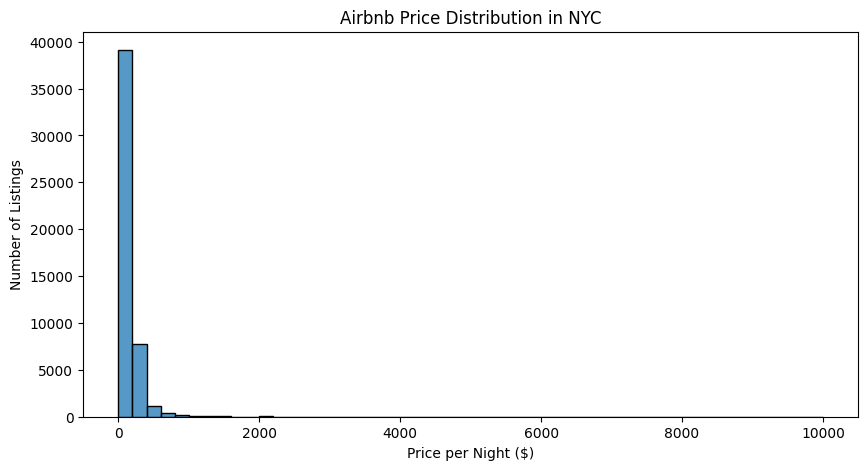

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='price', bins=50)

plt.title('Airbnb Price Distribution in NYC')
plt.xlabel('Price per Night ($)')
plt.ylabel('Number of Listings')

plt.show()

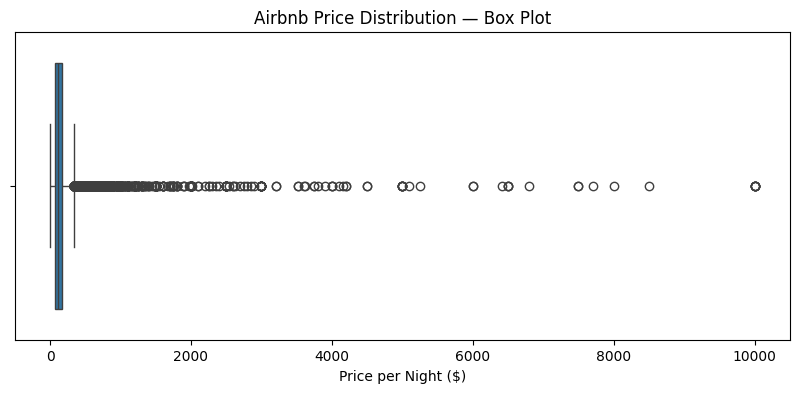

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_clean['price'])

plt.title('Airbnb Price Distribution — Box Plot')
plt.xlabel('Price per Night ($)')

plt.show()

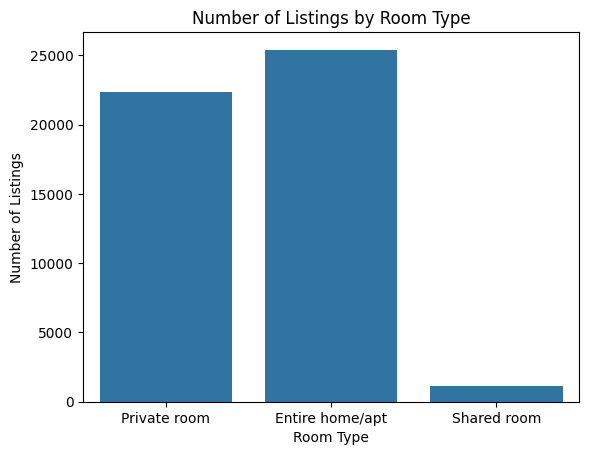

In [ ]:
sns.countplot(data=df, x='room_type')

plt.title('Number of Listings by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')
plt.xticks(rotation=0)
plt.show()


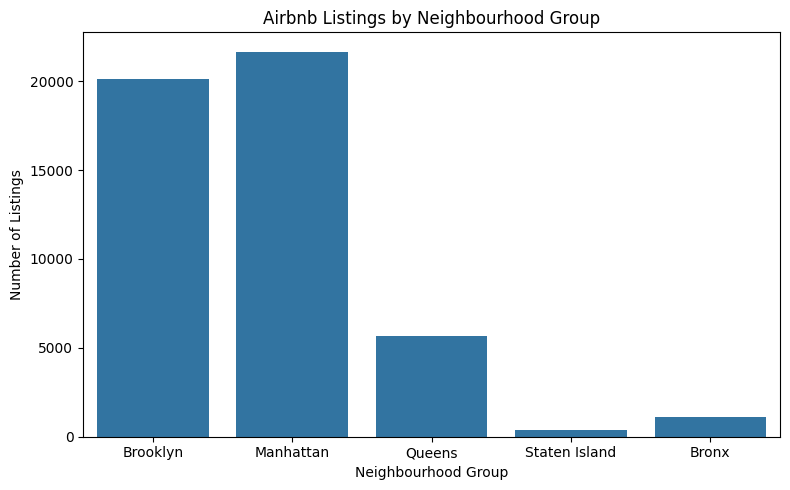

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='neighbourhood_group')

plt.title('Airbnb Listings by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

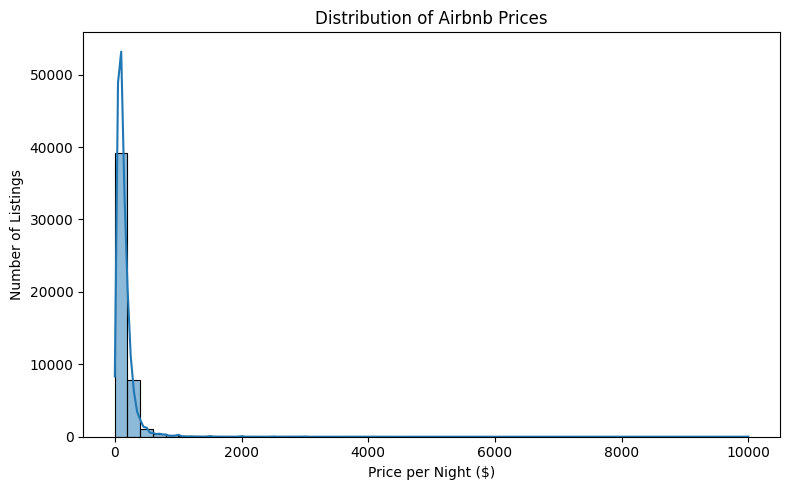

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='price', bins=50, kde=True)

plt.title('Distribution of Airbnb Prices')
plt.xlabel('Price per Night ($)')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

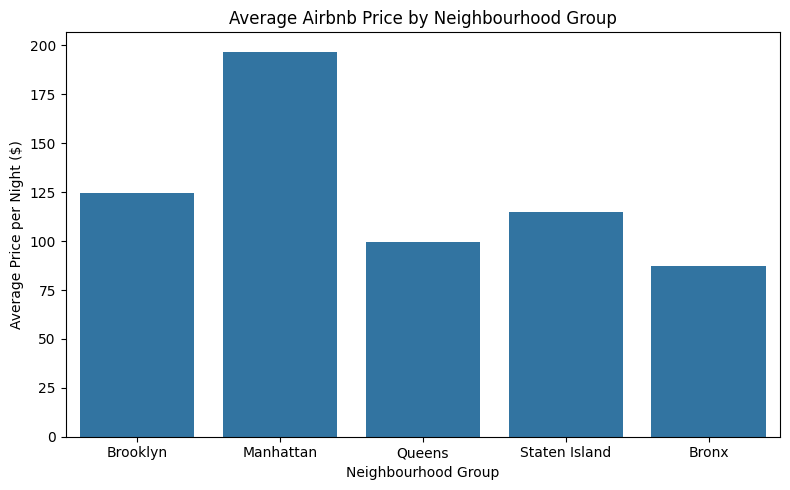

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='neighbourhood_group',
    y='price',
    errorbar=None
)

plt.title('Average Airbnb Price by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Average Price per Night ($)')
plt.tight_layout()
plt.show()

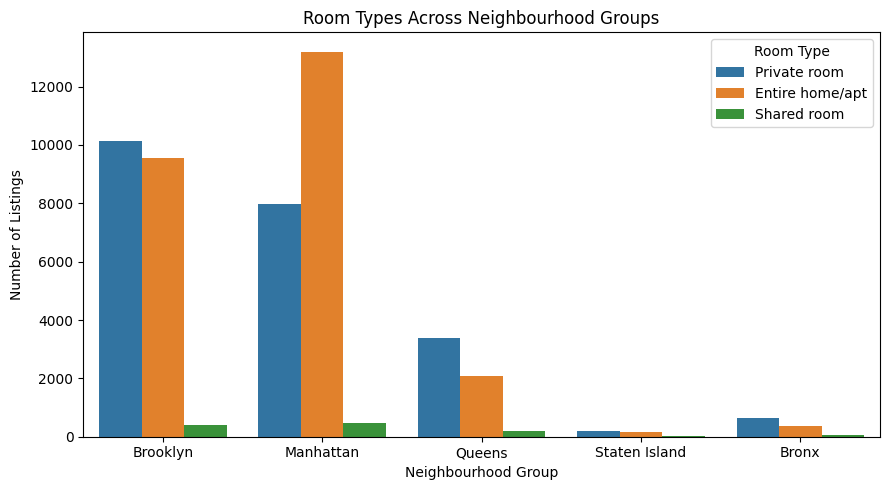

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='neighbourhood_group',
    hue='room_type'
)

plt.title('Room Types Across Neighbourhood Groups')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings')
plt.legend(title='Room Type')
plt.tight_layout()
plt.show()

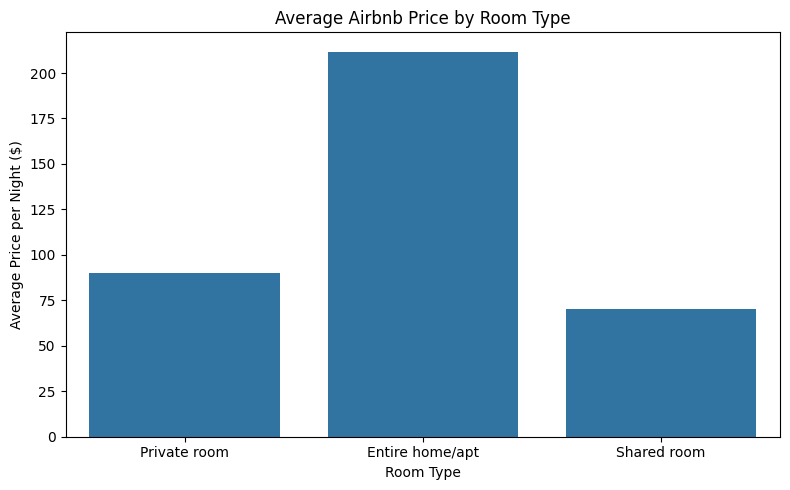

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='room_type',
    y='price',
    errorbar=None
)

plt.title('Average Airbnb Price by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Average Price per Night ($)')
plt.tight_layout()
plt.show()

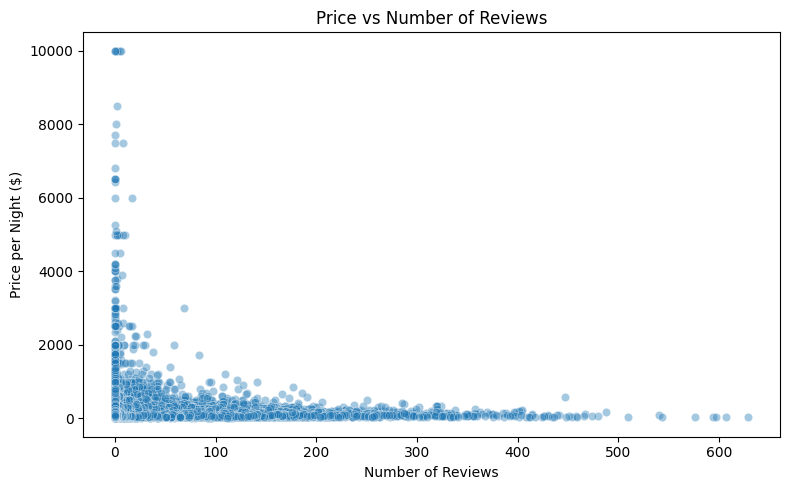

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='number_of_reviews',
    y='price',
    alpha=0.4
)

plt.title('Price vs Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Price per Night ($)')
plt.tight_layout()
plt.show()

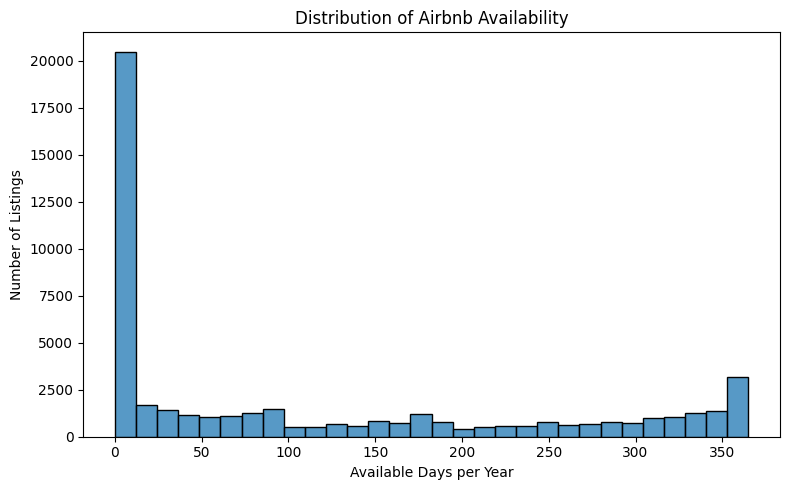

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='availability_365', bins=30)

plt.title('Distribution of Airbnb Availability')
plt.xlabel('Available Days per Year')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

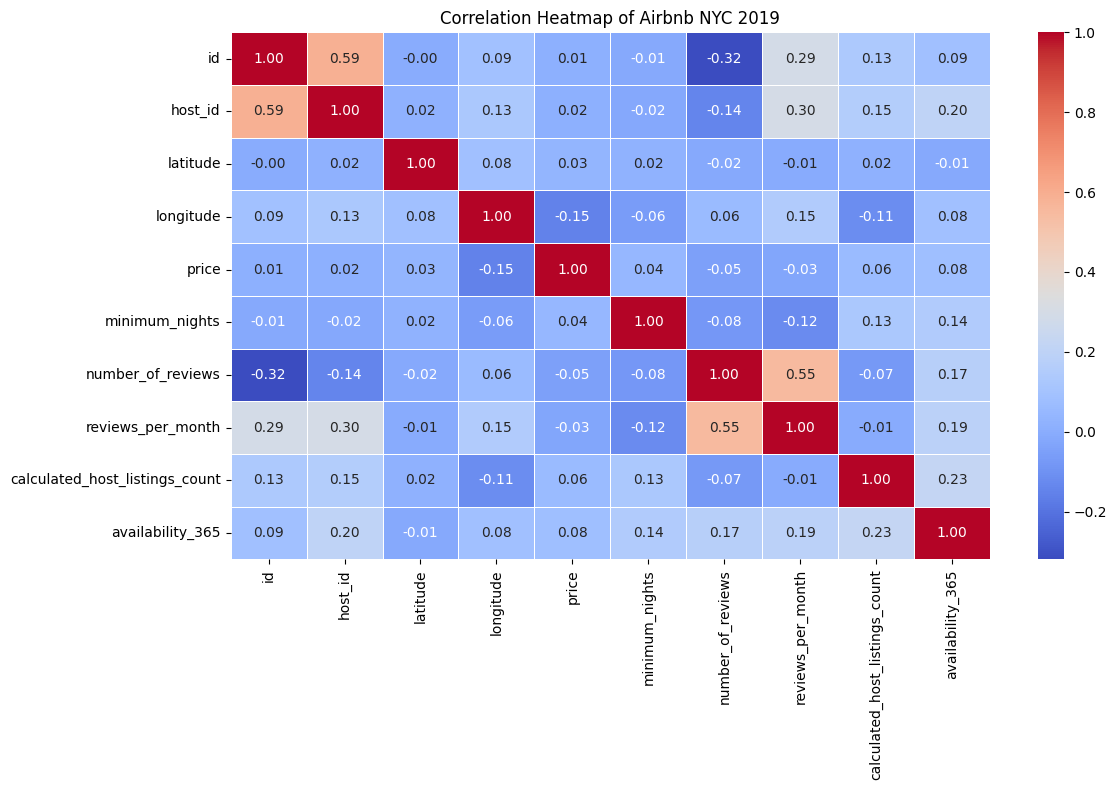

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Airbnb NYC 2019')
plt.tight_layout()
plt.show()

In [ ]:
df_clean.to_csv('AB_NYC_2019_Cleaned.csv', index=False)

In [ ]:
from google.colab import files

files.download('AB_NYC_2019_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>